# Phase 5 - Exploratory data analysis

This notebook regenerates the eight Phase 5 figures and presents the descriptive evidence behind the findings.

In [1]:
from pathlib import Path
import json
import subprocess
import sys
import pandas as pd
from IPython.display import Image, display

project_root = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
subprocess.run([sys.executable, '-m', 'src.eda'], cwd=project_root, check=True, stdout=subprocess.DEVNULL)
summary = json.loads((project_root / 'reports/generated/eda_summary.json').read_text(encoding='utf-8'))

In [2]:
pd.DataFrame(summary['metrics']).T

,count,mean,median,std,p05,p25,p75,p95,p99,min,max,skew
avg_d_mbps,15956.0,36.078125,27.8645,34.109506,4.36475,15.45975,45.45825,94.13025,168.09965,0.031,532.573,3.579497
avg_u_mbps,15956.0,14.779616,11.1160,12.868280,0.65775,4.56875,22.45550,39.26050,52.56585,0.001,170.529,1.361890
avg_lat_ms,15956.0,32.076774,27.0000,35.512385,17.00000,22.00000,32.00000,56.00000,154.00000,0.000,1138.000,13.859110
tests,15956.0,3.934883,2.0000,8.761942,1.00000,1.00000,4.00000,13.00000,36.00000,1.000,319.000,12.661287
devices,15956.0,1.860930,1.0000,2.602031,1.00000,1.00000,2.00000,5.00000,14.00000,1.000,58.000,7.288802


In [3]:
pd.DataFrame(summary['regional']).sort_values('weighted_download_mbps')

,adm1_name,tiles,tests,devices,median_download_mbps,weighted_download_mbps,weighted_upload_mbps,weighted_idle_latency_ms
2,Dhaka,4420,25540,11811,26.3485,33.797656,15.061621,26.380619
5,Rajshani,1582,4706,2356,25.0100,34.166719,13.874831,43.252231
0,Barisal,961,3385,1368,26.1360,35.049996,14.652451,32.151846
3,Khulna,1467,4203,2115,26.6820,35.797405,15.663153,30.637402
4,Mymensingh,709,1900,995,25.8850,38.349168,15.411994,28.628947
6,Rangpur,1524,4976,2195,24.2615,42.503375,15.057190,39.913987
1,Chittagong,4022,13813,6971,31.8350,42.783097,18.118409,33.092087
7,Sylhet,1271,4262,1882,34.5460,45.496427,20.453897,30.496715


In [4]:
{
    'correlations': summary['correlations'],
    'measurement_volume': summary['measurement_volume'],
    'screening_counts': summary['counts'],
}

{'correlations': {'pearson_download_latency': -0.07314869652526064,
  'spearman_download_latency': -0.15756385706244766,
  'pearson_tests_download': 0.02037272552083637,
  'spearman_tests_download': 0.14083778446770898},
 'measurement_volume': {'high': 427, 'low': 12797, 'medium': 2732},
 'screening_counts': {'download_below_10_mbps': 2264,
  'idle_latency_above_100_ms': 325,
  'loaded_latency_incomplete': 473}}

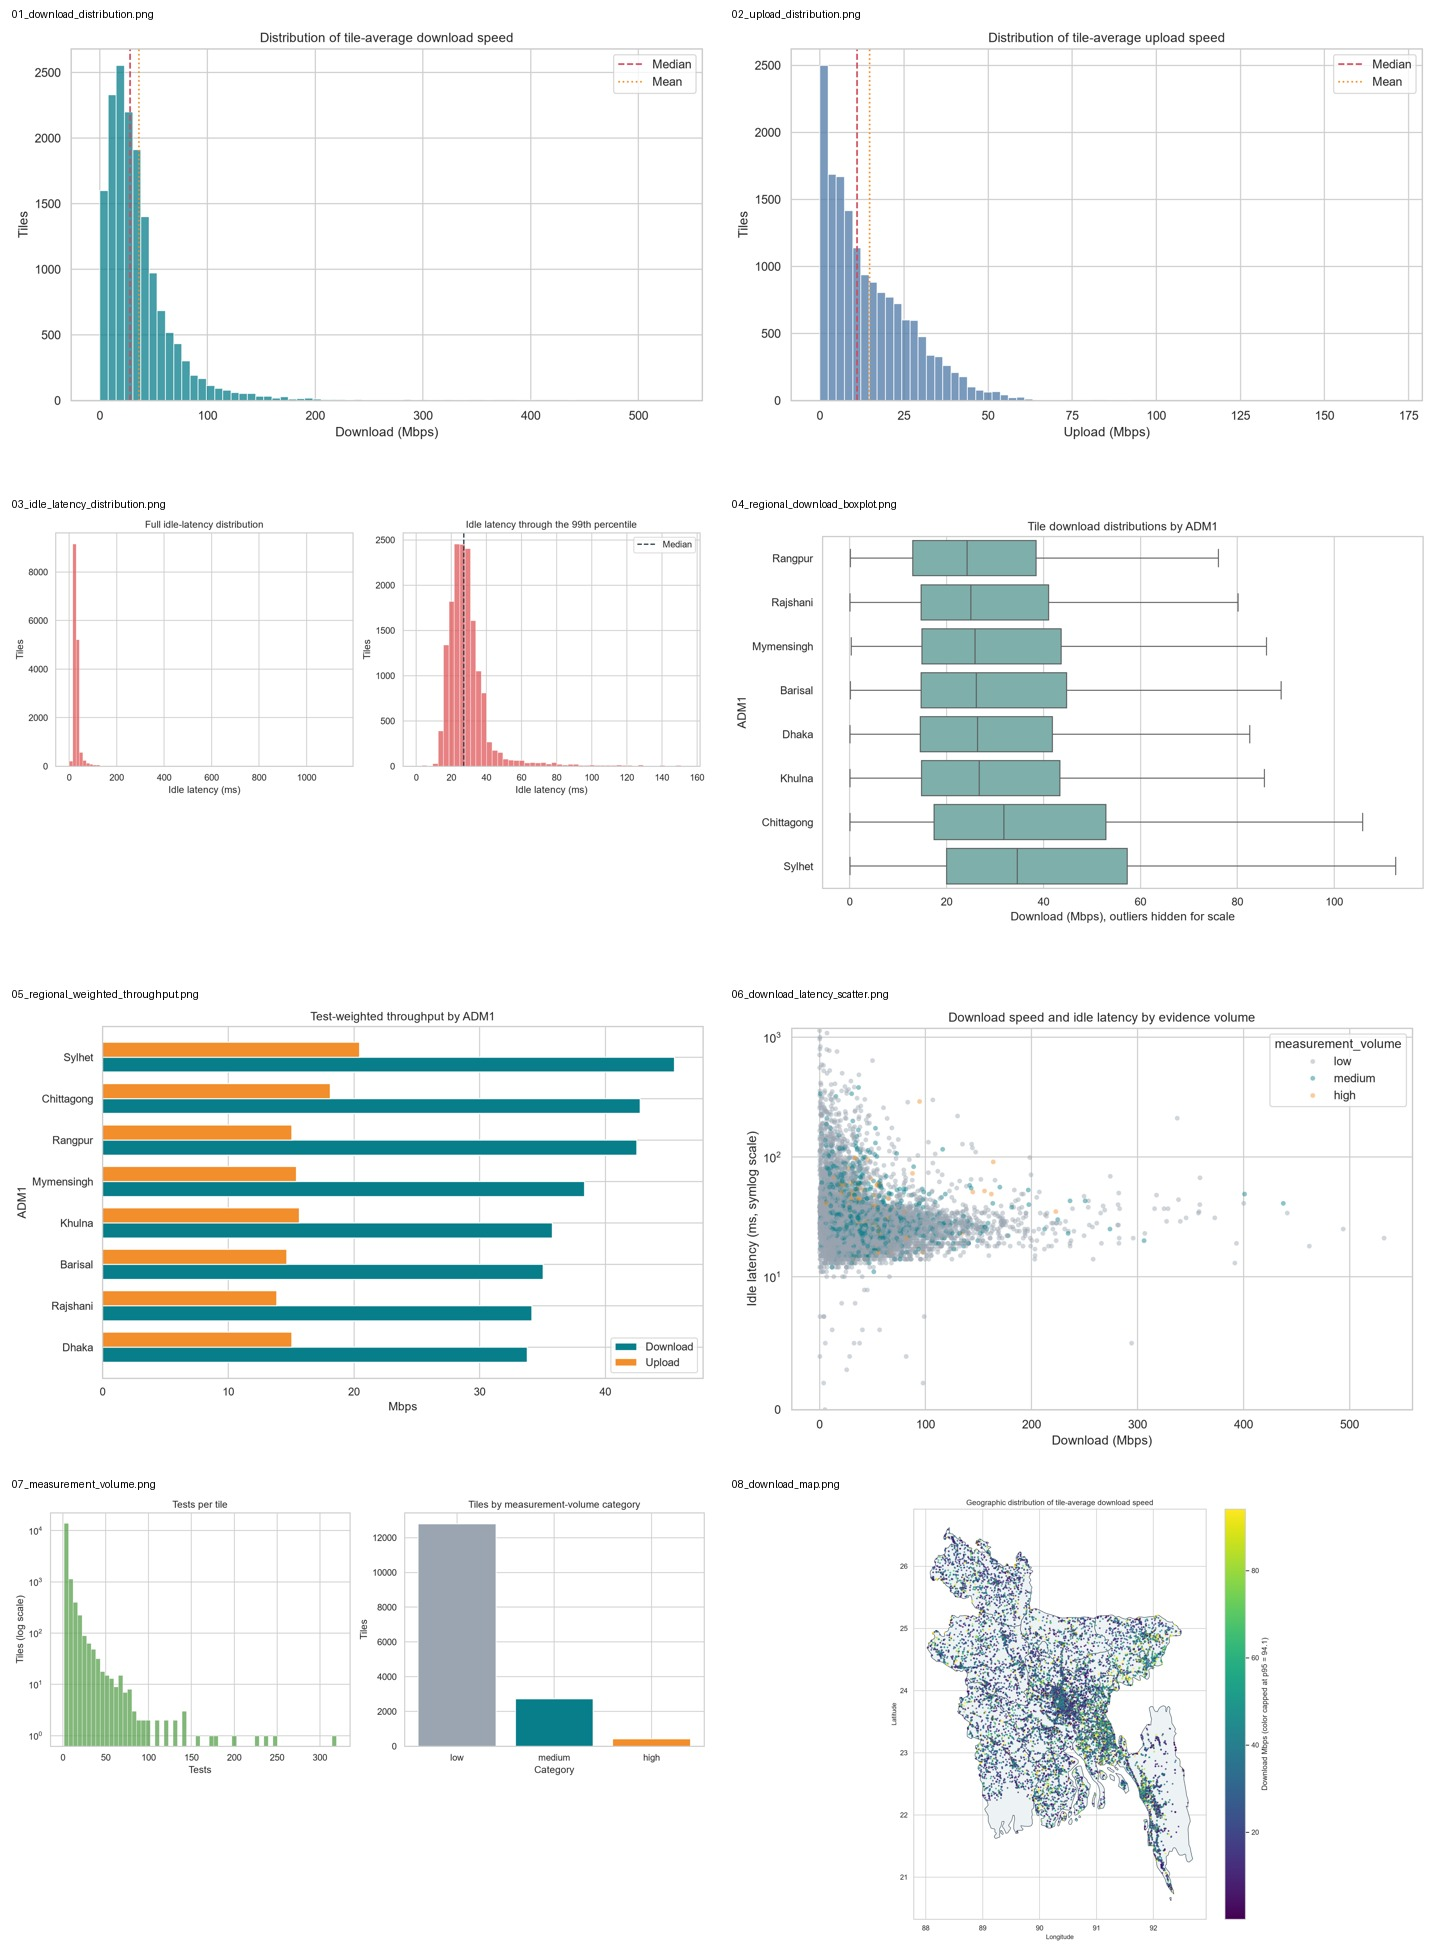

In [5]:
display(Image(filename=project_root / summary['contact_sheet']))

## Interpretation boundary

The figures describe aggregated Q4 2024 observations. They do not identify operators, coverage, outages, individual experience, or causal fault mechanisms.